# Indexes and Query Performance

A query that takes 2 ms on 1,000 rows can take 20 seconds on 10 million rows. **Indexes** let the database find rows without reading the whole table. `EXPLAIN ANALYZE` shows how the database executes a query, so you can see whether an index helps.

**After this lesson you can:**

1. Read `EXPLAIN ANALYZE` output: sequential scan, index scan, bitmap scan.
2. Create B-tree indexes, including composite and covering indexes.
3. Explain selectivity: when an index helps and when it does not.
4. Measure the cost of indexes on writes.

The experiments use a table with 2 million rows in the lab database.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

lab = create_engine(datasets.POSTGRES_URL.format(db="course"))   # a separate database for experiments

def run(sql: str) -> None:
    """Execute SQL statements (DDL/DML) in the lab database, in one transaction."""
    with lab.begin() as conn:
        if "$$" in sql:                       # function bodies contain ";" -> send the whole script at once
            conn.execute(text(sql))
            return
        for stmt in [s for s in sql.split(";") if s.strip()]:
            conn.execute(text(stmt))

def lq(sql: str, **params) -> pd.DataFrame:
    with lab.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

In [2]:
import time

run("""
DROP TABLE IF EXISTS orders;
CREATE TABLE orders AS
SELECT g AS order_id,
       (random() * 99999)::int + 1 AS customer_id,
       (ARRAY['new', 'paid', 'shipped', 'cancelled'])[1 + (random() * 3.999)::int] AS status,
       date '2023-01-01' + (random() * 730)::int AS order_date,
       round((random() * 500)::numeric, 2) AS amount
FROM generate_series(1, 2000000) g;
ANALYZE orders
""")
print(lq("SELECT count(*) AS rows, pg_size_pretty(pg_total_relation_size('orders')) AS size FROM orders"))

def explain(sql: str) -> str:
    plan = lq("EXPLAIN (ANALYZE, BUFFERS, COSTS OFF) " + sql)
    return "\n".join(plan.iloc[:, 0])

def timed(sql: str, repeat: int = 5) -> float:
    best = float("inf")
    for _ in range(repeat):
        t = time.perf_counter(); lq(sql); best = min(best, time.perf_counter() - t)
    return best * 1000

      rows    size
0  2000000  112 MB


## 1. Without an Index: Sequential Scan

To find the orders of one customer, PostgreSQL must read every row (**Seq Scan**). It uses several workers in parallel, but it still reads all 2 million rows.

In [3]:
query = "SELECT * FROM orders WHERE customer_id = 4242"
print(explain(query))
before = timed(query)
print(f"\nbest of 5: {before:.1f} ms")

Gather (actual time=25.391..63.453 rows=25 loops=1)
  Workers Planned: 2
  Workers Launched: 2
  Buffers: shared hit=2400 read=11872
  ->  Parallel Seq Scan on orders (actual time=10.059..45.205 rows=8 loops=3)
        Filter: (customer_id = 4242)
        Rows Removed by Filter: 666658
        Buffers: shared hit=2400 read=11872
Planning:
  Buffers: shared hit=20
Planning Time: 0.081 ms
Execution Time: 63.494 ms



best of 5: 62.3 ms


## 2. A B-tree Index

A **B-tree index** keeps the values of a column sorted in a balanced tree. The database descends the tree in a few steps ($O(\log n)$) and jumps to the matching rows. For a handful of matches, PostgreSQL uses an **Index Scan** or, as here, a **Bitmap Index Scan**: it collects the locations of all matching rows from the index first, then reads each needed table page once.

The "best of 5" time, measured from Python, includes the network round trip and pandas; the `Execution Time` in the plan is the time inside the database.

In [4]:
t = time.perf_counter()
run("CREATE INDEX idx_orders_customer ON orders (customer_id)")
build_s = time.perf_counter() - t
idx_size = lq("SELECT pg_size_pretty(pg_relation_size('idx_orders_customer')) AS s")["s"][0]
print(f"index built in {build_s:.1f} s, size: {idx_size}")
print(explain(query))
after = timed(query)
print(f"\nbest of 5: {after:.2f} ms -> {before / after:,.0f}x faster")

index built in 1.3 s, size: 15 MB
Bitmap Heap Scan on orders (actual time=0.099..0.227 rows=25 loops=1)
  Recheck Cond: (customer_id = 4242)
  Heap Blocks: exact=24
  Buffers: shared hit=5 read=22
  ->  Bitmap Index Scan on idx_orders_customer (actual time=0.071..0.071 rows=25 loops=1)
        Index Cond: (customer_id = 4242)
        Buffers: shared read=3
Planning:
  Buffers: shared hit=4 read=1
Planning Time: 0.153 ms
Execution Time: 0.240 ms

best of 5: 2.34 ms -> 27x faster


## 3. Selectivity: When an Index Does Not Help

**Selectivity** is the fraction of rows that a condition keeps. An index helps when the condition keeps **few** rows. If it keeps a large fraction, reading the whole table sequentially is cheaper than jumping around the index, and the planner ignores the index. The experiment filters on `amount < x` for growing `x` and records the plan and the time.

In [5]:
run("CREATE INDEX idx_orders_amount ON orders (amount); ANALYZE orders")
rows = []
for limit in [0.5, 2, 10, 50, 150, 300, 500]:
    sql = f"SELECT count(*), avg(amount) FROM orders WHERE amount < {limit}"
    plan = explain(sql)
    scan = "Bitmap" if "Bitmap" in plan else "Index" if "Index" in plan else "Seq"     # check Bitmap first
    frac = lq(f"SELECT avg((amount < {limit})::int) AS f FROM orders")["f"][0]
    rows.append({"amount <": limit, "fraction of rows": round(float(frac), 4), "plan": scan, "ms": round(timed(sql, 3), 1)})
sel = pd.DataFrame(rows)
sel

,amount <,fraction of rows,plan,ms
0,0.5,0.0010,Bitmap,5.2
1,2.0,0.0040,Bitmap,10.1
2,10.0,0.0201,Bitmap,27.5
3,50.0,0.0997,Bitmap,84.5
4,150.0,0.2998,Seq,127.9
5,300.0,0.5992,Seq,147.8
6,500.0,1.0000,Seq,171.7


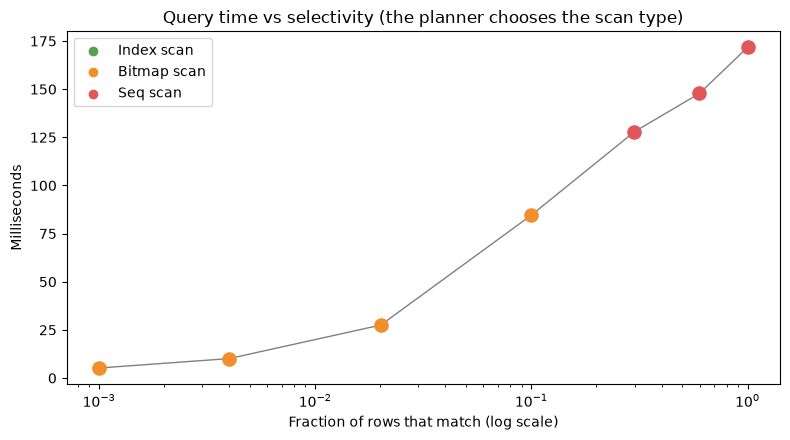

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"Index": "#59A14F", "Bitmap": "#F28E2B", "Seq": "#E15759"}
ax.plot(sel["fraction of rows"], sel["ms"], color="grey", lw=1)
for _, r in sel.iterrows():
    ax.scatter(r["fraction of rows"], r["ms"], s=90, color=colors[r["plan"]], zorder=3)
for plan, color in colors.items():
    ax.scatter([], [], color=color, label=f"{plan} scan")
ax.set(xscale="log", title="Query time vs selectivity (the planner chooses the scan type)",
       xlabel="Fraction of rows that match (log scale)", ylabel="Milliseconds")
ax.legend()
plt.tight_layout()
plt.show()

For selective conditions the planner uses the index (here as a bitmap index scan). When a condition matches a large share of the table (about 30 % or more in this run), it switches to a sequential scan, which is cheaper than jumping between index and table for so many rows. The planner makes this choice from **statistics** that `ANALYZE` collects; outdated statistics are a common cause of bad plans.

## 4. Composite and Covering Indexes

- A **composite index** on `(customer_id, order_date)` serves filters on `customer_id` alone and on `customer_id` + `order_date`, but **not** on `order_date` alone (the leftmost column rule).
- A **covering index** includes all columns the query needs (`INCLUDE (amount)`), so PostgreSQL answers from the index alone: an **Index Only Scan**.

In [7]:
run("DROP INDEX idx_orders_customer; CREATE INDEX idx_cust_date ON orders (customer_id, order_date) INCLUDE (amount)")
with lab.connect().execution_options(isolation_level="AUTOCOMMIT") as conn:   # VACUUM cannot run in a transaction
    conn.execute(text("VACUUM ANALYZE orders"))
q1 = "SELECT order_date, amount FROM orders WHERE customer_id = 4242 AND order_date >= '2024-01-01'"
q2 = "SELECT count(*) FROM orders WHERE order_date = '2024-03-01'"
for label, sql in [("customer + date", q1), ("date only", q2)]:
    scans = [line.strip() for line in explain(sql).splitlines() if "Scan" in line]
    print(f"{label:<16}: {scans[0]}")

customer + date : Index Only Scan using idx_cust_date on orders (actual time=0.041..0.043 rows=11 loops=1)
date only       : ->  Parallel Seq Scan on orders (actual time=0.088..44.531 rows=928 loops=3)


The first query uses an index-only scan. The second filters only on `order_date`, the second column of the index, so PostgreSQL cannot use the index tree efficiently and scans the table.

## 5. The Cost of Indexes on Writes

Every index must be updated on every `INSERT`, `UPDATE` and `DELETE`, and it uses disk space. The experiment inserts 200,000 rows into a table with 0, 2 and 4 indexes.

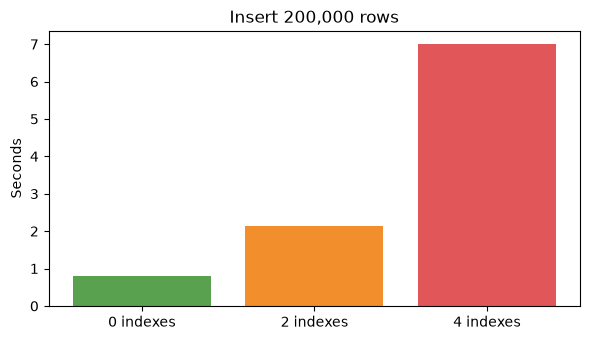

{0: '0.80 s', 2: '2.13 s', 4: '7.00 s'}


In [8]:
run("DROP TABLE IF EXISTS src; CREATE UNLOGGED TABLE src AS "
    "SELECT g AS a, (random()*1e6)::int AS b, md5(g::text) AS c, date '2024-01-01' + g % 365 AS d FROM generate_series(1, 200000) g")
write_cost = {}
for n_idx in (0, 2, 4):
    runs = []
    for _ in range(3):                                   # best of 3 runs: removes noise from checkpoints and caches
        run("DROP TABLE IF EXISTS w; CREATE TABLE w (a int, b int, c text, d date)")
        for i, col in enumerate(["a", "b", "c", "d"][:n_idx]):
            run(f"CREATE INDEX w_idx_{i} ON w ({col})")
        t = time.perf_counter()
        run("INSERT INTO w SELECT * FROM src")
        runs.append(time.perf_counter() - t)
    write_cost[n_idx] = min(runs)
run("DROP TABLE w; DROP TABLE src")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([f"{k} indexes" for k in write_cost], write_cost.values(), color=["#59A14F", "#F28E2B", "#E15759"])
ax.set(title="Insert 200,000 rows", ylabel="Seconds")
plt.tight_layout()
plt.show()
print({k: f"{v:.2f} s" for k, v in write_cost.items()})

*Insight: Index the columns that appear in selective `WHERE`, `JOIN` and `ORDER BY` clauses of frequent queries, and verify each index with `EXPLAIN ANALYZE`. Do not index everything: every index slows down writes and uses space.*

## Real-World Use Case or Analogy

An index is like the **index at the back of a textbook**. To find "photosynthesis", you look it up and jump to page 212 instead of reading the whole book. But if you want every page that contains the word "the", the index does not help: reading the book from start to end is faster. And every time a new edition adds pages, the publisher must update the index (the write cost).

Performance tuning in production usually starts with `EXPLAIN ANALYZE` on the slowest queries (found with `pg_stat_statements`). One missing index on a foreign key can make an application page take seconds instead of milliseconds.